# Predicción de Churn Telefonía móvil

Las comunicaciones por teléfono móvil siempre han sido objeto de una feroz competencia, en la que, usualmente, hay un número reducido de competidores (operadores) en el mercado que oscila entre cuatro y seis. Los operadores deben hacer fuertes inversiones de entrada para poder operar y prestar un servicio adecuado. El mercado de telefonía móvil está usualmente saturado (poca posibilidad de ampliación del mercado) y, por tanto, el conjunto de consumidores disponibles es reducido, por lo que los operadores usualmente cambian su estrategia de adquisición de clientes a una de retención, pues en el mundo se calcula que el costo de adquirir un nuevo cliente es cinco veces superior al de retenerlo- El esfuerzo fundamental se centra en predecir la deserción (churn) para poderla prevenir.

Un operador de telecomunicaciones les ha contratado para tener una mejor predicción de churn. Les otorga una base de datos de entrenamiento (que es una muestra aleatoria simple de la base de datos total de la compañía) que contiene el resultado de retención en los últimos seis meses y les pide que se realice la mejor predicción posible (basada en el área bajo la curva COR) para una base de datos de prueba en un concurso de Kaggle. Pide también un reporte con metodología CRISP-DM (de máximo 6 páginas) de los modelos realizados.

## Importación de librerias y datos

In [ ]:
%pip install pandas openpyxl scikit-learn

In [2]:
import pandas as pd
import numpy as np

In [ ]:
data_train = pd.read_excel('./files/traintelco.xlsx')
data_test = pd.read_excel('./files/testelco.xlsx')

In [9]:
data_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8243 entries, 0 to 8242
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   id                     8243 non-null   int64         
 1   Fecha de nacimiento    8243 non-null   datetime64[ns]
 2   tipo cliente           8243 non-null   int64         
 3   Factura online         8243 non-null   int64         
 4   Antigüedad Equipo      8243 non-null   int64         
 5   Plan de datos          8243 non-null   int64         
 6   facturación            8243 non-null   int64         
 7   mora                   8243 non-null   int64         
 8   Fecha inicio contrato  8243 non-null   datetime64[ns]
 9   minutos                8243 non-null   int64         
 10  resultado              8243 non-null   int64         
dtypes: datetime64[ns](2), int64(9)
memory usage: 708.5 KB


In [60]:
data_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   id                     2000 non-null   int64         
 1   Fecha de nacimiento    2000 non-null   datetime64[ns]
 2   tipo cliente           2000 non-null   int64         
 3   Factura online         2000 non-null   int64         
 4   Antigüedad Equipo      2000 non-null   int64         
 5   Plan de datos          2000 non-null   int64         
 6   facturación            2000 non-null   int64         
 7   mora                   2000 non-null   int64         
 8   Fecha inicio contrato  2000 non-null   datetime64[ns]
 9   minutos                2000 non-null   int64         
dtypes: datetime64[ns](2), int64(8)
memory usage: 156.4 KB


## Limpieza de datos

In [88]:
data_train_clean = data_train.copy()
data_test_clean = data_test.copy()

Calculo de la edad de la persona para reemplazarlo por la fecha de nacimiento, se considera como un dato predictivo de mayor peso

In [89]:
# Calculate age from birth year and drop birth year
def calculate_age(df):
    df['age'] = 2018 - df['Fecha de nacimiento'].dt.year
    df = df.drop(columns=['Fecha de nacimiento'])
    return df

data_train_clean = calculate_age(data_train_clean)
data_test_clean = calculate_age(data_test_clean)

Dummificación de el tipo de cliente

In [90]:
# Dummy variables for 'tipo cliente' and drop 'tipo cliente'
def dummy(df, columns):
    df = pd.get_dummies(df, columns=columns)
    df = df.rename(columns={'tipo cliente_1': 'hombre', 'tipo cliente_2': 'mujer', 'tipo cliente_3': 'empresarial'})
    return df

columns = ['tipo cliente']
data_train_clean = dummy(data_train_clean, columns)
data_test_clean = dummy(data_test_clean, columns)

Se cambia el valor de fecha de contrato por una variable cuantitativa que representa qué tan nuevo es el contrato

In [91]:
# Extract timestamp from date
def extract_timestamp(df):
    column = 'Fecha inicio contrato'
    df[column] = pd.to_datetime(df[column])
    df[column] = df[column].astype(np.int64) // 10**9
    df = df.rename(columns={'Fecha inicio contrato': 'novedad del contrato'})
    return df

data_train_clean = extract_timestamp(data_train_clean)
data_test_clean = extract_timestamp(data_test_clean)

Estandarización de variables cuantitativas

In [92]:
# Standardize numerical variables
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
columns = ['novedad del contrato', 'facturación', 'mora', 'minutos', 'Antigüedad Equipo', 'age']

data_train_clean[columns] = scaler.fit_transform(data_train_clean[columns])
data_test_clean[columns] = scaler.transform(data_test_clean[columns])

In [93]:
# Drop id column
data_train_clean = data_train_clean.drop(columns=['id'])
# save ids in a separate dataframe for later
ids = data_test_clean['id']
data_test_clean = data_test_clean.drop(columns=['id'])

In [94]:
data_train_clean

,Factura online,Antigüedad Equipo,Plan de datos,facturación,mora,novedad del contrato,minutos,resultado,age,hombre,mujer,empresarial
0,1,-1.007978,0,-2.334734,0.754564,1.023311,-0.578726,0,-6.585613,False,True,False
1,0,1.104213,1,0.771149,-0.719395,0.598030,-0.558356,0,-4.542519,False,True,False
2,0,0.906195,1,-0.388154,0.088905,0.514947,-0.155260,1,-5.359756,False,True,False
3,1,-0.875966,1,-0.653097,-0.434113,0.204387,-0.695581,0,-5.768375,False,True,False
4,1,-1.205996,0,1.692216,-0.862036,-1.495751,0.734555,0,-5.768375,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
8238,1,-1.139990,1,-0.746119,0.421734,-0.083921,8.265818,1,-0.660641,False,True,False
8239,1,-0.743954,0,-0.106995,-0.719395,0.282078,-0.559428,0,-0.864950,True,False,False
8240,1,-0.941972,1,0.212065,1.087393,1.054913,0.301441,0,-0.660641,False,True,False
8241,0,0.576165,1,-0.629130,-0.719395,0.631053,-0.739535,0,2.199690,True,False,False


## Entrenamiento del modelo

División de variables predictoras y dependiente y Cross Validation

In [95]:
X = data_train_clean.drop(columns=['resultado'])
Y = data_train_clean['resultado']

from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

### Modelos

Entrenamiento del modelo

In [121]:
# LOGISTIC REGRESSION
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, Y_train)

LogisticRegression()

In [143]:
# MODEL: CHAID DECISION TREE
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(criterion='gini', random_state=42)
model.fit(X_train, Y_train)

DecisionTreeClassifier(random_state=42)

Evaluación del modelo

In [144]:
# evaluate model
y_pred = model.predict(X_test)

from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, roc_auc_score

accuracy = accuracy_score(Y_test, y_pred)
f1 = f1_score(Y_test, y_pred)
recall_score = recall_score(Y_test, y_pred)
precision_score = precision_score(Y_test, y_pred)
auc = roc_auc_score(Y_test, y_pred)

print(f'Accuracy: {accuracy}')
print(f'F1 score: {f1}')
print(f'Recall: {recall_score}')
print(f'Precision: {precision_score}')
print(f'AUC: {auc}')

Accuracy: 0.8101879927228623
F1 score: 0.436036036036036
Recall: 0.4384057971014493
Precision: 0.4336917562724014
AUC: 0.6616646611144537


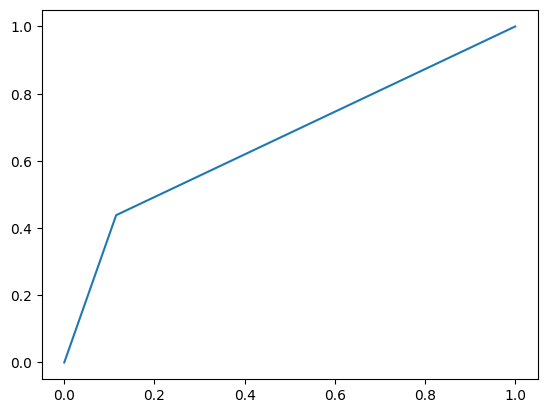

In [145]:
# Calculate AUC and PLOT ROC curve
from sklearn.metrics import roc_curve

y_pred_proba = model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(Y_test, y_pred_proba)

import matplotlib.pyplot as plt
plt.plot(fpr, tpr)

### Creacion de sometimiento

In [146]:
# use the model to predict the test data
y_test_pred = model.predict(data_test_clean)

# save the predictions to a csv file
submission = pd.DataFrame({'id': ids, 'resultado': y_test_pred})
submission.to_csv('submission.csv', index=False)

Grupo:
- Esteban Salazar Arbeláez
- Juan Francisco Ramírez Escobar
- Javier Alejandro Moyano Cipamocha